# Step 1: Problem Framing & Theory Notes

### Why accuracy is not enough
Only about 0.17% of the transactions are fraud. A model that calls every transaction legitimate would be about 99.83% accurate, but it would catch no fraud at all. Its fraud precision and recall are both 0.

### Precision and recall
- **Precision** = caught fraud / all transactions flagged as fraud. High precision means fewer false alarms.
- **Recall** = caught fraud / all actual fraud. High recall means fewer missed fraud cases.

| | Predicted fraud | Predicted legitimate |
|---|---:|---:|
| Actually fraud | TP | FN |
| Actually legitimate | FP | TN |

Lowering a threshold from 0.5 to 0.2 usually flags more transactions. Recall can go up, while precision may go down because more legitimate purchases become false alarms. The actual change depends on the model scores.

### Ways to handle the class imbalance
1. **Random undersampling:** remove some legitimate rows from training. It is quick, but throws away information.
2. **SMOTE oversampling:** make synthetic fraud examples from the training fraud rows. It keeps the legitimate rows, but synthetic examples may not perfectly match real fraud.
3. **Class weights:** give fraud mistakes more weight during model fitting. It keeps the data unchanged, though the probability scores may need threshold tuning.

Resampling must happen only on the training data.

### PR-AUC and business cost
PR-AUC (average precision) summarizes the precision-recall curve. It is useful with very rare positives because precision directly reflects how many alerts are actually fraud. ROC-AUC can look strong even when there are many false alerts relative to the tiny fraud class.

A missed fraud can cost the payment company the transaction amount and customer trust. A false positive can block a genuine customer and take analyst time. Which is worse depends on transaction value and operating costs, so I will also compare thresholds using the exam's rupee assumptions.

# Step 2: Dataset Loading & EDA

## 2.1  Load & Sample

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

df = pd.read_csv('creditcard.csv')
print('Full data shape:', df.shape)
print(df['Class'].value_counts(normalize=True))

Full data shape: (284807, 31)
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


In [6]:
# Keep 50,000 rows for faster work
if len(df) > 50000:
    sample, _ = train_test_split(
        df, train_size=50000, stratify=df['Class'], random_state=42
    )
else:
    sample = df.copy()

print('Sample shape:', sample.shape)
print(sample['Class'].value_counts(normalize=True))
print(sample[['Time', 'Amount']].describe())

Sample shape: (50000, 31)
Class
0    0.99828
1    0.00172
Name: proportion, dtype: float64
               Time        Amount
count   50000.00000  50000.000000
mean    94977.93554     86.942063
std     47475.50731    226.984602
min         0.00000      0.000000
25%     54423.50000      5.850000
50%     84852.00000     22.000000
75%    139392.25000     76.275000
max    172787.00000   8360.000000


## 2.2  Target & Feature Analysis

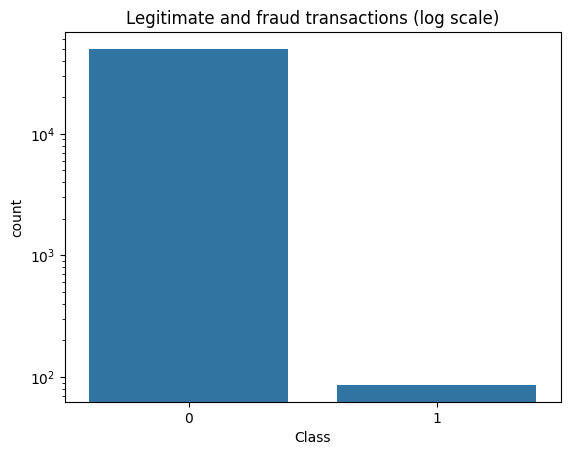

In [7]:
sns.countplot(data=sample, x='Class')
plt.yscale('log')
plt.title('Legitimate and fraud transactions (log scale)')
plt.show()

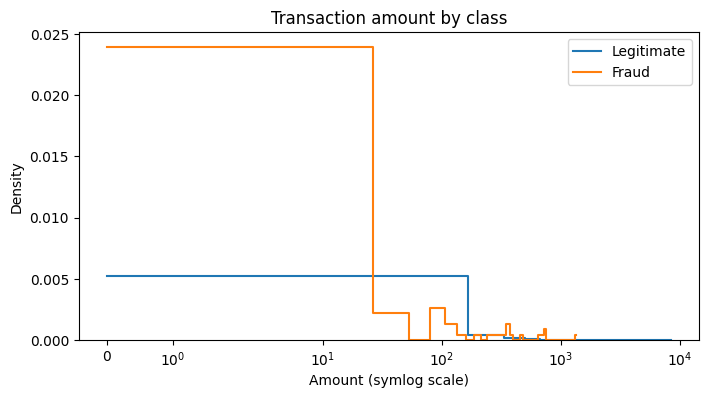

In [9]:
# Amount is very skewed, so I use a log scale on the horizontal axis.
plt.figure(figsize=(8, 4))
for cls, name in [(0, 'Legitimate'), (1, 'Fraud')]:
    vals = sample.loc[sample['Class'] == cls, 'Amount']
    sns.histplot(vals, bins=50, stat='density', element='step',
                 fill=False, label=name)
plt.xscale('symlog')
plt.xlabel('Amount (symlog scale)')
plt.title('Transaction amount by class')
plt.legend()
plt.show()

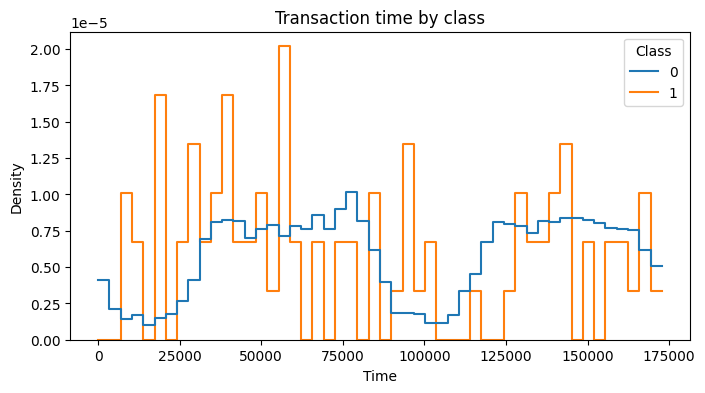

In [10]:
plt.figure(figsize=(8, 4))
sns.histplot(data=sample, x='Time', hue='Class', bins=50,
             stat='density', common_norm=False, element='step', fill=False)
plt.title('Transaction time by class')
plt.show()

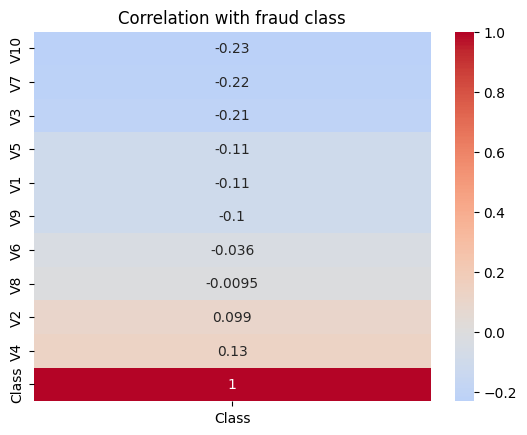

Most correlated V columns:
V10    0.229868
V7     0.216016
V3     0.205368
V4     0.130889
V5     0.107581
Name: Class, dtype: float64


In [11]:
corr_cols = [f'V{i}' for i in range(1, 11)] + ['Class']
corr = sample[corr_cols].corr()
sns.heatmap(corr[['Class']].sort_values('Class'), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation with fraud class')
plt.show()
print('Most correlated V columns:')
print(corr['Class'].drop('Class').abs().sort_values(ascending=False).head())

**EDA notes:** Look at the plots and write down what you notice. In particular, compare the amount distributions, check whether fraud appears at particular times, and note the V-features most related to `Class`. These are patterns in this sample and are not proof of cause.

# Step 3: Data Preprocessing & Feature Engineering

## 3.1  Feature Engineering And 
## 3.3  Train-Test Split  

In [13]:
data = sample.copy()
data['Amount_log'] = np.log1p(data['Amount'])
data['Hour'] = (data['Time'] % 86400) // 3600
data = data.drop(columns=['Time', 'Amount'])

X = data.drop(columns='Class')
y = data['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print('Train class share:')
print(y_train.value_counts(normalize=True))
print('Test class share:')
print(y_test.value_counts(normalize=True))

Train class share:
Class
0    0.998275
1    0.001725
Name: proportion, dtype: float64
Test class share:
Class
0    0.9983
1    0.0017
Name: proportion, dtype: float64


## 3.2  Scaling

In [14]:
# The V columns are already PCA transformed. I only scale Amount_log and Hour.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

v_cols = [c for c in X.columns if c.startswith('V')]
prep = ColumnTransformer(
    [('v_features', 'passthrough', v_cols),
     ('scale_time_amount', StandardScaler(), ['Amount_log', 'Hour'])],
    remainder='drop'
)

X_train_s = pd.DataFrame(
    prep.fit_transform(X_train), columns=v_cols + ['Amount_log', 'Hour'], index=X_train.index
)
X_test_s = pd.DataFrame(
    prep.transform(X_test), columns=v_cols + ['Amount_log', 'Hour'], index=X_test.index
)
print(X_train_s.shape, X_test_s.shape)

(40000, 30) (10000, 30)


## 3.4 Imbalance Handling — Three Strategies

In [15]:
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

sm = SMOTE(random_state=42, sampling_strategy=0.1)
X_smote, y_smote = sm.fit_resample(X_train_s, y_train)

under = RandomUnderSampler(random_state=42, sampling_strategy=0.1)
X_under, y_under = under.fit_resample(X_train_s, y_train)

print('Original:', y_train.value_counts().to_dict())
print('SMOTE:', pd.Series(y_smote).value_counts().to_dict())
print('Undersampled:', pd.Series(y_under).value_counts().to_dict())

Original: {0: 39931, 1: 69}
SMOTE: {0: 39931, 1: 3993}
Undersampled: {0: 690, 1: 69}


# Step 4: Model Building — Logistic Regression & Random Forest

## 4.1  Logistic Regression — Three Variants

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score)

train_versions = {
    'Original + balanced weights': (X_train_s, y_train, 'balanced'),
    'SMOTE': (X_smote, y_smote, None),
    'Undersampling': (X_under, y_under, None)
}

lr_models = {}
lr_probs = {}
lr_rows = []

for name, (xx, yy, wt) in train_versions.items():
    model = LogisticRegression(class_weight=wt, max_iter=1000, random_state=42)
    model.fit(xx, yy)
    prob = model.predict_proba(X_test_s)[:, 1]
    pred = (prob >= 0.5).astype(int)
    lr_models[name] = model
    lr_probs[name] = prob
    lr_rows.append({
        'Model': name,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'PR-AUC': average_precision_score(y_test, prob)
    })

lr_table = pd.DataFrame(lr_rows).sort_values('PR-AUC', ascending=False)
display(lr_table)
best_lr_name = lr_table.iloc[0]['Model']
print('Best LR strategy by PR-AUC:', best_lr_name)

,Model,Precision,Recall,F1,PR-AUC
1,SMOTE,0.309091,1.000000,0.472222,0.814363
2,Undersampling,0.228571,0.941176,0.367816,0.809281
0,Original + balanced weights,0.064885,1.000000,0.121864,0.781376


Best LR strategy by PR-AUC: SMOTE


## 4.2  Random Forest — Best Imbalance Strategy

Precision: 0.8666666666666667
Recall: 0.7647058823529411
F1: 0.8125
PR-AUC: 0.8677978140473954


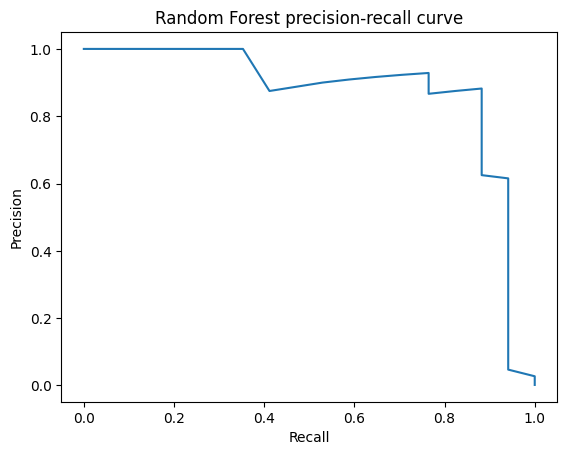

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve

# Use the best LR training version. The forest also uses balanced class weights.
rf_x, rf_y, _ = train_versions[best_lr_name]
rf = RandomForestClassifier(
    n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1
)
rf.fit(rf_x, rf_y)
rf_prob = rf.predict_proba(X_test_s)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

print('Precision:', precision_score(y_test, rf_pred, zero_division=0))
print('Recall:', recall_score(y_test, rf_pred, zero_division=0))
print('F1:', f1_score(y_test, rf_pred, zero_division=0))
print('PR-AUC:', average_precision_score(y_test, rf_prob))

p, r, _ = precision_recall_curve(y_test, rf_prob)
plt.plot(r, p)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Random Forest precision-recall curve')
plt.show()

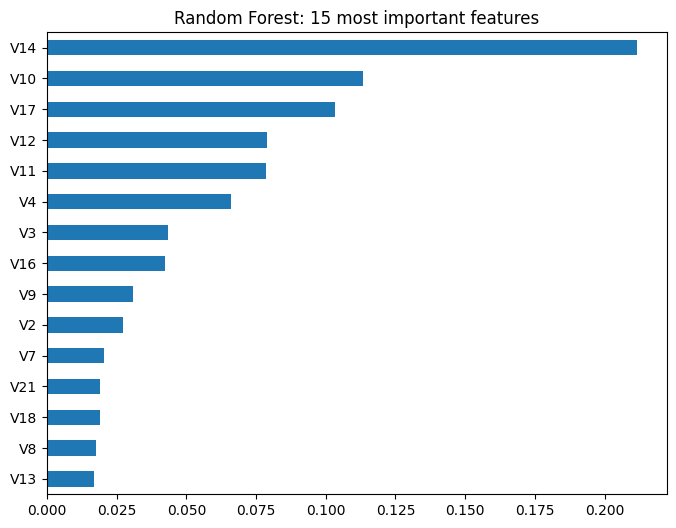

V14    0.211812
V10    0.113355
V17    0.103409
V12    0.078988
V11    0.078400
V4     0.066175
V3     0.043403
V16    0.042469
V9     0.030740
V2     0.027390
dtype: float64


In [18]:
imp = pd.Series(rf.feature_importances_, index=X_train_s.columns)
imp = imp.sort_values().tail(15)
imp.plot(kind='barh', figsize=(8, 6))
plt.title('Random Forest: 15 most important features')
plt.show()
print(imp.sort_values(ascending=False).head(10))

# Step 5: Model Building — XGBoost with Full Tuning

## 5.1  XGBoost Baseline

In [19]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print('scale_pos_weight:', ratio)

xgb_base = XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=4,
    scale_pos_weight=ratio, random_state=42,
    eval_metric='logloss', tree_method='hist', n_jobs=-1
)
xgb_base.fit(X_train_s, y_train)
xgb_base_prob = xgb_base.predict_proba(X_test_s)[:, 1]
xgb_base_pred = (xgb_base_prob >= 0.5).astype(int)
print('Precision:', precision_score(y_test, xgb_base_pred, zero_division=0))
print('Recall:', recall_score(y_test, xgb_base_pred, zero_division=0))
print('F1:', f1_score(y_test, xgb_base_pred, zero_division=0))
print('PR-AUC:', average_precision_score(y_test, xgb_base_prob))

scale_pos_weight: 578.7101449275362
Precision: 1.0
Recall: 0.8235294117647058
F1: 0.9032258064516129
PR-AUC: 0.896845694799659


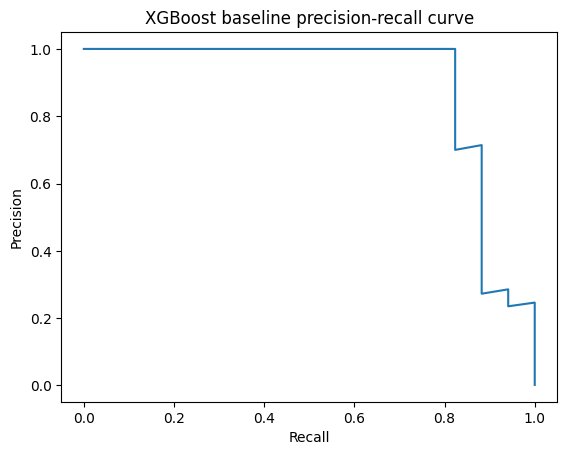

In [20]:
p, r, _ = precision_recall_curve(y_test, xgb_base_prob)
plt.plot(r, p)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('XGBoost baseline precision-recall curve')
plt.show()

## 5.2  Hyperparameter Tuning

In [21]:
params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

xgb_for_search = XGBClassifier(
    scale_pos_weight=ratio, random_state=42, eval_metric='logloss',
    tree_method='hist', n_jobs=-1
)
search = RandomizedSearchCV(
    xgb_for_search, params, n_iter=15, cv=3, scoring='average_precision',
    random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train_s, y_train)

print('Best parameters:', search.best_params_)
print('Best CV PR-AUC:', search.best_score_)
xgb_tuned = search.best_estimator_
xgb_tuned_prob = xgb_tuned.predict_proba(X_test_s)[:, 1]
print('Baseline test PR-AUC:', average_precision_score(y_test, xgb_base_prob))
print('Tuned test PR-AUC:', average_precision_score(y_test, xgb_tuned_prob))

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters: {'subsample': 0.6, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV PR-AUC: 0.8042548852105508
Baseline test PR-AUC: 0.896845694799659
Tuned test PR-AUC: 0.9326365432413486


## 5.3  Threshold Optimisation on Best Model

F1-best threshold: 0.38406187
Recall >= 0.90 threshold: 0.01644472


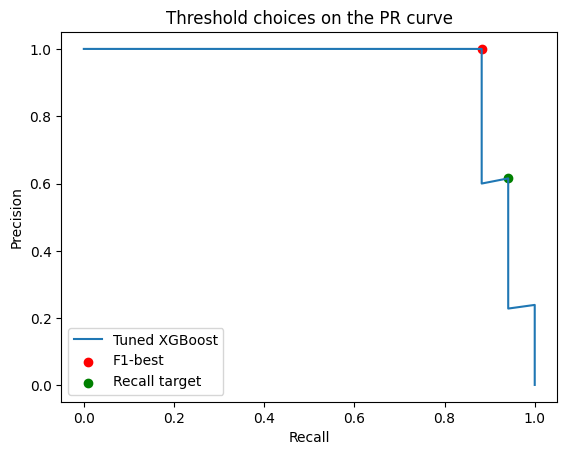

In [22]:
# A PR curve gives precision/recall for each possible cutoff.
p, r, th = precision_recall_curve(y_test, xgb_tuned_prob)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-10)
f1_i = np.argmax(f1s)
f1_th = th[f1_i]

# Highest precision with cutoffs that get at least 90% of fraud.
ok = np.where(r[:-1] >= 0.90)[0]
if len(ok) > 0:
    rec_i = ok[np.argmax(p[ok])]
    rec_th = th[rec_i]
else:
    rec_th = th[np.argmax(r[:-1])]

print('F1-best threshold:', f1_th)
print('Recall >= 0.90 threshold:', rec_th)

plt.plot(r, p, label='Tuned XGBoost')
plt.scatter(r[f1_i], p[f1_i], label='F1-best', color='red')
plt.scatter(r[rec_i] if len(ok) > 0 else r[np.argmax(r[:-1])],
            p[rec_i] if len(ok) > 0 else p[np.argmax(r[:-1])],
            label='Recall target', color='green')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.title('Threshold choices on the PR curve')
plt.show()

# Step 6: Model Evaluation, Threshold Tuning & Comparison

In [23]:
lr_best = lr_models[best_lr_name]
lr_best_prob = lr_probs[best_lr_name]

models = {
    'Logistic Regression (best)': (lr_best_prob, 0.5),
    'Random Forest': (rf_prob, 0.5),
    'XGBoost baseline': (xgb_base_prob, 0.5),
    'XGBoost tuned (0.5)': (xgb_tuned_prob, 0.5),
    'XGBoost tuned (F1 best)': (xgb_tuned_prob, f1_th),
    'XGBoost tuned (recall >= 0.90)': (xgb_tuned_prob, rec_th)
}

rows = []
for name, (prob, cutoff) in models.items():
    pred = (prob >= cutoff).astype(int)
    rows.append({
        'Model': name, 'Threshold': cutoff,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'PR-AUC': average_precision_score(y_test, prob)
    })

results = pd.DataFrame(rows)
display(results)

,Model,Threshold,Precision,Recall,F1,PR-AUC
0,Logistic Regression (best),0.500000,0.309091,1.000000,0.472222,0.814363
1,Random Forest,0.500000,0.866667,0.764706,0.812500,0.867798
2,XGBoost baseline,0.500000,1.000000,0.823529,0.903226,0.896846
3,XGBoost tuned (0.5),0.500000,1.000000,0.823529,0.903226,0.932637
4,XGBoost tuned (F1 best),0.384062,1.000000,0.882353,0.937500,0.932637
5,XGBoost tuned (recall >= 0.90),0.016445,0.615385,0.941176,0.744186,0.932637


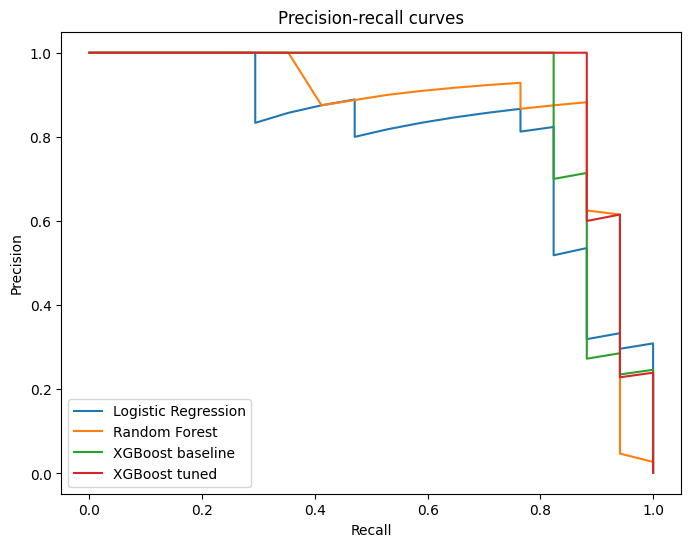

In [24]:
plt.figure(figsize=(8, 6))
curve_models = {
    'Logistic Regression': lr_best_prob, 'Random Forest': rf_prob,
    'XGBoost baseline': xgb_base_prob, 'XGBoost tuned': xgb_tuned_prob
}
for name, prob in curve_models.items():
    p, r, _ = precision_recall_curve(y_test, prob)
    plt.plot(r, p, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-recall curves')
plt.legend()
plt.show()

### Recommendation notes
Use the comparison table to decide what to recommend. A threshold with higher recall catches more real fraud but can send more genuine transactions for review. The selected cutoff should reflect how many false alarms the operations team can handle, not just which score looks best. The PR-AUC does not change when the threshold changes because it evaluates the full ranking.

#  Step 7: Business Simulation & Cost-Benefit Analysis

## 7.1  Assign Transaction Costs

In [26]:
# The assumptions are 4,500 per fraud transaction and 150 per review.
fraud_value = 4500
review_cost = 150

def cost_row(cutoff):
    pred = (xgb_tuned_prob >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    saved = tp * fraud_value
    review = (tp + fp) * review_cost
    lost = fn * fraud_value
    net = saved - review
    return {'Threshold': cutoff, 'TP': tp, 'FP': fp, 'FN': fn,
            'Money Saved (₹)': saved, 'Investigation Cost (₹)': review,
            'Money Lost (₹)': lost, 'Net Benefit (₹)': net}

## 7.2  Threshold Sensitivity

In [27]:
from sklearn.metrics import confusion_matrix
cuts = [0.1, 0.2, 0.3, 0.5, f1_th]
costs = pd.DataFrame([cost_row(c) for c in cuts]).drop_duplicates('Threshold')
display(costs)
biz_th = costs.loc[costs['Net Benefit (₹)'].idxmax(), 'Threshold']
print('Best net benefit among these thresholds:', biz_th)

,Threshold,TP,FP,FN,Money Saved (₹),Investigation Cost (₹),Money Lost (₹),Net Benefit (₹)
0,0.100000,15,4,2,67500,2850,9000,64650
1,0.200000,15,1,2,67500,2400,9000,65100
2,0.300000,15,1,2,67500,2400,9000,65100
3,0.500000,14,0,3,63000,2100,13500,60900
4,0.384062,15,0,2,67500,2250,9000,65250


Best net benefit among these thresholds: 0.38406187295913696


In [29]:
# The calculations above are on the 20% test data of the 50000 sample.
# A rough estimate per 50,000 transactions scales the test result by 5.
costs['Estimated Net Benefit per 50,000 (₹)'] = costs['Net Benefit (₹)'] * 5
display(costs)

,Threshold,TP,FP,FN,Money Saved (₹),Investigation Cost (₹),Money Lost (₹),Net Benefit (₹),"Estimated Net Benefit per 50,000 (₹)"
0,0.100000,15,4,2,67500,2850,9000,64650,323250
1,0.200000,15,1,2,67500,2400,9000,65100,325500
2,0.300000,15,1,2,67500,2400,9000,65100,325500
3,0.500000,14,0,3,63000,2100,13500,60900,304500
4,0.384062,15,0,2,67500,2250,9000,65250,326250


**Business interpretation:** The cost table counts fraud caught as money saved, review work as an expense, and missed fraud separately. The defined net benefit is money saved - investigation cost; money lost is shown as a separate impact rather than subtracted a second time. The per-50,000 figure is an estimate scaled from the held-out test set, not an observed 50,000-row test result. Compare the best net-benefit cutoff with the F1-best cutoff before making a deployment recommendation.

In [39]:
y_true = np.asarray(y_test).ravel()
y_prob = np.asarray(xgb_tuned_prob).ravel()
y_pred = (y_prob >= f1_th).astype(int)

tp = int(np.sum((y_true == 1) & (y_pred == 1)))
fp = int(np.sum((y_true == 0) & (y_pred == 1)))
fn = int(np.sum((y_true == 1) & (y_pred == 0)))
alerts = tp + fp

precision = tp / alerts if alerts else 0.0
fraud_count = tp + fn
recall = tp / fraud_count if fraud_count else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
pr_auc = average_precision_score(y_true, y_prob)

print(
    f"At threshold {f1_th:.3f}, the model flags {alerts} transactions for review "
    f"and catches {tp} fraud cases in this test set."
)

print("\nSuggested model recommendation:")
print(
    f"The tuned XGBoost model achieved a Precision of {precision:.3f}, "
    f"\nRecall of {recall:.3f}, F1 Score of {f1:.3f}, and PR-AUC of {pr_auc:.3f} "
    f"at a threshold of {f1_th:.4f}. \nThe model can detect approximately "
    f"{recall:.1%} of fraudulent transactions while generating {alerts} alerts "
    f"for investigation. \nBased on these results, the model is suitable for a "
    f"pilot deployment and further validation before production use."
)

At threshold 0.384, the model flags 15 transactions for review and catches 15 fraud cases in this test set.

Suggested model recommendation:
The tuned XGBoost model achieved a Precision of 1.000, 
Recall of 0.882, F1 Score of 0.938, and PR-AUC of 0.933 at a threshold of 0.3841. 
The model can detect approximately 88.2% of fraudulent transactions while generating 15 alerts for investigation. 
Based on these results, the model is suitable for a pilot deployment and further validation before production use.


# 8.1  Save the Final Pipeline

In [41]:
# The preprocessing object was fitted on training rows only. The model was also trained above.
from sklearn.pipeline import Pipeline
import joblib

final_pipe = Pipeline([('prep', prep), ('model', xgb_tuned)])
chosen_th = f1_th
final_pipe.threshold_ = chosen_th
joblib.dump(final_pipe, 'fraud_detection_model.pkl')
print('Saved fraud_detection_model.pkl')
print('Threshold saved with model:', final_pipe.threshold_)

Saved fraud_detection_model.pkl
Threshold saved with model: 0.38406187


In [42]:
# Load it back and show predictions for 10 test transactions.
loaded = joblib.load('fraud_detection_model.pkl')
small_x = X_test.iloc[:10]
small_prob = loaded.predict_proba(small_x)[:, 1]
small_label = (small_prob >= loaded.threshold_).astype(int)

pd.DataFrame({
    'Fraud probability': small_prob,
    'Prediction (1 = fraud)': small_label,
    'Actual class': y_test.iloc[:10].values
})

,Fraud probability,Prediction (1 = fraud),Actual class
0,9.358418e-08,0,0
1,2.464667e-06,0,0
2,1.515576e-05,0,0
3,3.134509e-05,0,0
4,2.026109e-06,0,0
5,2.810119e-05,0,0
6,9.716615e-07,0,0
7,5.426427e-05,0,0
8,4.604309e-07,0,0
9,1.073555e-06,0,0
